# 🌳 Decision Tree from Scratch vs. scikit-learn
A fully self-contained notebook: the algorithm is implemented in Section 2 with NumPy only, then benchmarked against scikit-learn on the Breast Cancer Wisconsin dataset.

**Contents:** 1. Setup and data · 2. Algorithm from scratch · 3. Comparison · 4. Overfitting vs. depth · 5. Feature importance · 6. Tree diagram · 7. Random Forest extension

## 1. Setup and data exploration

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

data = load_breast_cancer(as_frame=True)
df = data.frame
print('Shape:', df.shape, '| missing values:', int(df.isna().sum().sum()))
df['target'].map(dict(enumerate(data.target_names))).value_counts()

Shape: (569, 31) | missing values: 0


target
benign       357
malignant    212
Name: count, dtype: int64

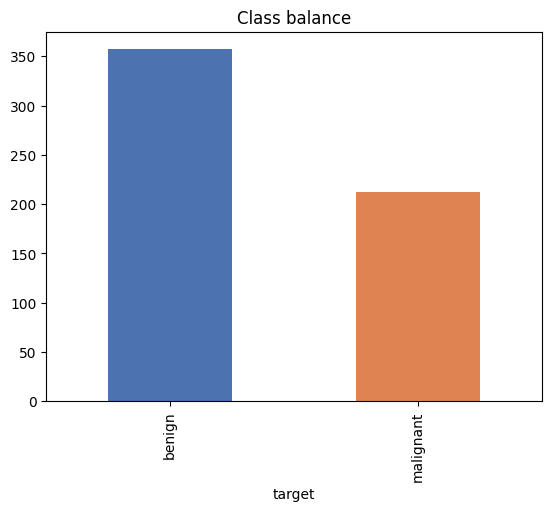

In [2]:
df['target'].map(dict(enumerate(data.target_names))).value_counts().plot.bar(title='Class balance', color=['#4C72B0','#DD8452']);

In [3]:
df.groupby('target')[['mean radius','mean texture','worst radius','worst concave points']].mean().rename(index=dict(enumerate(data.target_names)))

,mean radius,mean texture,worst radius,worst concave points
target,,,,
malignant,17.462830,21.604906,21.134811,0.182237
benign,12.146524,17.914762,13.379801,0.074444


## 2. The algorithm from scratch
**Gini impurity** = 1 − Σpₖ²  ·  **Entropy** = −Σpₖ·log₂pₖ  ·  **Information gain** = parent impurity − weighted child impurity.

At each node the tree tries every feature and every midpoint threshold, keeps the split with the highest gain, and recurses until a stopping rule (`max_depth`, `min_samples_split`, or a pure node) is hit.

In [4]:
import numpy as np


def gini(y):
    """Gini impurity: 1 - sum(p_k^2)."""
    if len(y) == 0:
        return 0.0
    p = np.bincount(y) / len(y)
    return 1.0 - np.sum(p ** 2)


def entropy(y):
    """Shannon entropy: -sum(p_k * log2 p_k)."""
    if len(y) == 0:
        return 0.0
    p = np.bincount(y) / len(y)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


class Node:
    __slots__ = ("feature", "threshold", "left", "right", "value", "n", "impurity")

    def __init__(self, value, n, impurity, feature=None, threshold=None, left=None, right=None):
        self.value, self.n, self.impurity = value, n, impurity
        self.feature, self.threshold, self.left, self.right = feature, threshold, left, right

    @property
    def is_leaf(self):
        return self.feature is None


class DecisionTree:
    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self._impurity = gini if criterion == "gini" else entropy

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
        self.n_classes_ = int(y.max()) + 1
        self.n_features_ = X.shape[1]
        self.feature_importances_ = np.zeros(self.n_features_)
        self.root_ = self._build(X, y, depth=0)
        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        return self

    def _best_split(self, X, y):
        """Search every feature and every midpoint threshold for the max information gain."""
        n, parent = len(y), self._impurity(y)
        best = (None, None, 0.0)  # feature, threshold, gain
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j])
            xs, ys = X[order, j], y[order]
            # incremental class counts keep each feature O(n) after sorting
            left_counts = np.zeros(self.n_classes_)
            right_counts = np.bincount(ys, minlength=self.n_classes_).astype(float)
            for i in range(n - 1):
                c = ys[i]
                left_counts[c] += 1
                right_counts[c] -= 1
                if xs[i] == xs[i + 1]:
                    continue
                nl, nr = i + 1, n - i - 1
                if nl < self.min_samples_leaf or nr < self.min_samples_leaf:
                    continue
                pl, pr = left_counts / nl, right_counts / nr
                if self.criterion == "gini":
                    il, ir = 1 - np.sum(pl ** 2), 1 - np.sum(pr ** 2)
                else:
                    il = -np.sum(pl[pl > 0] * np.log2(pl[pl > 0]))
                    ir = -np.sum(pr[pr > 0] * np.log2(pr[pr > 0]))
                gain = parent - (nl / n) * il - (nr / n) * ir
                if gain > best[2]:
                    best = (j, (xs[i] + xs[i + 1]) / 2, gain)
        return best

    def _build(self, X, y, depth):
        n = len(y)
        imp = self._impurity(y)
        value = np.bincount(y, minlength=self.n_classes_)
        stop = (imp == 0 or n < self.min_samples_split
                or (self.max_depth is not None and depth >= self.max_depth))
        if not stop:
            j, thr, gain = self._best_split(X, y)
            if j is not None:
                self.feature_importances_[j] += gain * n
                mask = X[:, j] <= thr
                left = self._build(X[mask], y[mask], depth + 1)
                right = self._build(X[~mask], y[~mask], depth + 1)
                return Node(value, n, imp, j, thr, left, right)
        return Node(value, n, imp)

    def _predict_one(self, x):
        node = self.root_
        while not node.is_leaf:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return int(np.argmax(node.value))

    def predict(self, X):
        return np.array([self._predict_one(x) for x in np.asarray(X, dtype=float)])

    def get_depth(self):
        def d(node):
            return 0 if node.is_leaf else 1 + max(d(node.left), d(node.right))
        return d(self.root_)

    def export_text(self, feature_names=None, class_names=None):
        lines = []
        def rec(node, indent):
            pad = "|   " * indent
            if node.is_leaf:
                c = int(np.argmax(node.value))
                lines.append(f"{pad}class: {class_names[c] if class_names else c}  (n={node.n})")
                return
            name = feature_names[node.feature] if feature_names else f"x[{node.feature}]"
            lines.append(f"{pad}{name} <= {node.threshold:.3f}")
            rec(node.left, indent + 1)
            lines.append(f"{pad}{name} >  {node.threshold:.3f}")
            rec(node.right, indent + 1)
        rec(self.root_, 0)
        return "\n".join(lines)


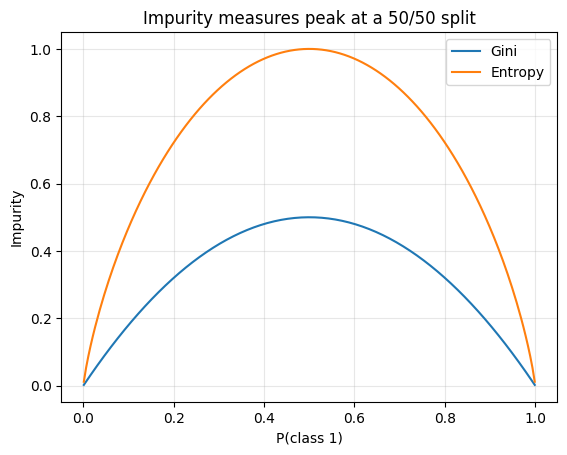

In [5]:
p = np.linspace(0.001, 0.999, 200)
plt.plot(p, 1-p**2-(1-p)**2, label='Gini'); plt.plot(p, -p*np.log2(p)-(1-p)*np.log2(1-p), label='Entropy')
plt.xlabel('P(class 1)'); plt.ylabel('Impurity'); plt.title('Impurity measures peak at a 50/50 split'); plt.legend(); plt.grid(alpha=.3);

## 3. Train and compare
75/25 stratified split, `random_state=42`, `max_depth=5` for both trees.

In [6]:
def metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred),
            'recall': recall_score(y_true, y_pred), 'f1': f1_score(y_true, y_pred)}

X, y, names = data.data.values, data.target.values, list(data.feature_names)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

mine = DecisionTree('gini', max_depth=5).fit(Xtr, ytr)
sk = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(Xtr, ytr)

results = pd.DataFrame({'From scratch': metrics(yte, mine.predict(Xte)), 'scikit-learn': metrics(yte, sk.predict(Xte)), 'Random Forest': metrics(yte, rf.predict(Xte))}).T
(results * 100).round(2)

,accuracy,precision,recall,f1
From scratch,93.71,95.51,94.44,94.97
scikit-learn,93.71,95.51,94.44,94.97
Random Forest,95.80,95.65,97.78,96.70


In [7]:
print('Prediction agreement with scikit-learn:', (mine.predict(Xte) == sk.predict(Xte)).mean())

Prediction agreement with scikit-learn: 1.0


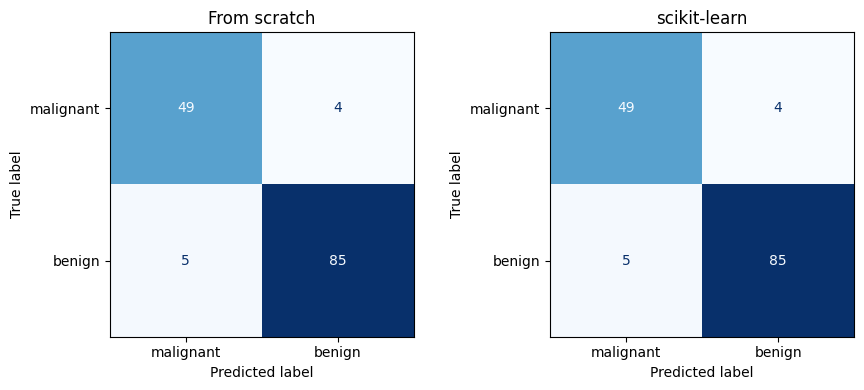

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, (t, pr) in zip(ax, [('From scratch', mine.predict(Xte)), ('scikit-learn', sk.predict(Xte))]):
    ConfusionMatrixDisplay(confusion_matrix(yte, pr), display_labels=data.target_names).plot(ax=a, colorbar=False, cmap='Blues'); a.set_title(t)
plt.tight_layout();

In [9]:
print(mine.export_text(names, list(data.target_names)))

worst radius <= 16.795
|   worst concave points <= 0.136
|   |   radius error <= 1.048
|   |   |   radius error <= 0.626
|   |   |   |   smoothness error <= 0.003
|   |   |   |   |   class: benign  (n=4)
|   |   |   |   smoothness error >  0.003
|   |   |   |   |   class: benign  (n=243)
|   |   |   radius error >  0.626
|   |   |   |   mean texture <= 18.630
|   |   |   |   |   class: malignant  (n=1)
|   |   |   |   mean texture >  18.630
|   |   |   |   |   class: benign  (n=3)
|   |   radius error >  1.048
|   |   |   class: malignant  (n=1)
|   worst concave points >  0.136
|   |   worst texture <= 25.620
|   |   |   mean smoothness <= 0.123
|   |   |   |   worst area <= 817.100
|   |   |   |   |   class: benign  (n=9)
|   |   |   |   worst area >  817.100
|   |   |   |   |   class: malignant  (n=1)
|   |   |   mean smoothness >  0.123
|   |   |   |   class: malignant  (n=2)
|   |   worst texture >  25.620
|   |   |   worst symmetry <= 0.268
|   |   |   |   mean radius <= 14.440
|

## 4. Overfitting vs. tree depth

Best test depth: 4 | best test accuracy: 0.951


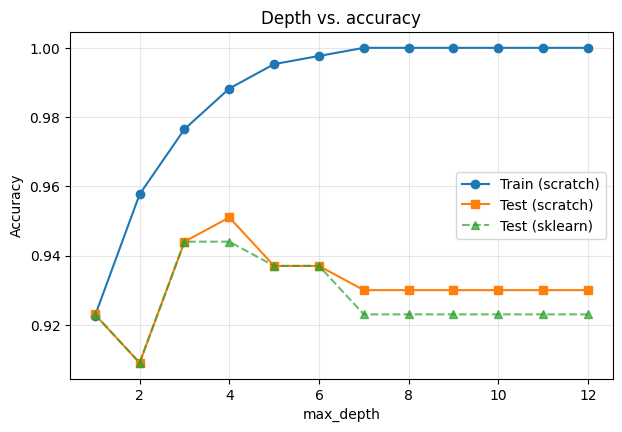

In [10]:
depths = range(1, 13)
tr, te, ske = [], [], []
for d in depths:
    m = DecisionTree('gini', max_depth=d).fit(Xtr, ytr)
    tr.append((m.predict(Xtr) == ytr).mean()); te.append((m.predict(Xte) == yte).mean())
    ske.append(DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xtr, ytr).score(Xte, yte))
plt.figure(figsize=(7, 4.5))
plt.plot(depths, tr, 'o-', label='Train (scratch)'); plt.plot(depths, te, 's-', label='Test (scratch)'); plt.plot(depths, ske, '^--', label='Test (sklearn)', alpha=.7)
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.title('Depth vs. accuracy'); plt.grid(alpha=.3); plt.legend()
print('Best test depth:', list(depths)[int(np.argmax(te))], '| best test accuracy:', round(max(te), 4))

In [11]:
pd.DataFrame({'min_samples_split': [2, 5, 10, 20, 40],
    'test_accuracy': [(DecisionTree('gini', min_samples_split=s).fit(Xtr, ytr).predict(Xte) == yte).mean() for s in [2, 5, 10, 20, 40]]}).round(4)

,min_samples_split,test_accuracy
0,2,0.9301
1,5,0.9371
2,10,0.9301
3,20,0.9441
4,40,0.9091


## 5. Feature importance

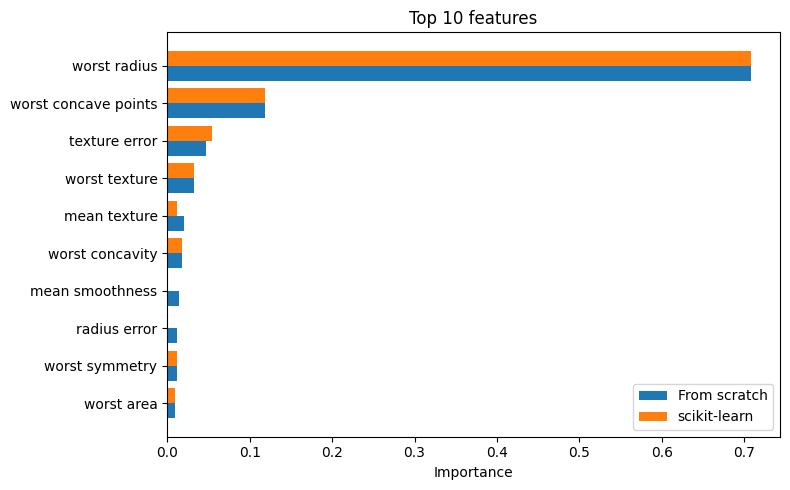

In [12]:
idx = np.argsort(mine.feature_importances_)[::-1][:10]
plt.figure(figsize=(8, 5)); w = 0.4; pos = np.arange(10)
plt.barh(pos - w/2, mine.feature_importances_[idx][::-1], w, label='From scratch')
plt.barh(pos + w/2, sk.feature_importances_[idx][::-1], w, label='scikit-learn')
plt.yticks(pos, [names[i] for i in idx][::-1]); plt.xlabel('Importance'); plt.title('Top 10 features'); plt.legend(); plt.tight_layout();

## 6. Tree diagram
scikit-learn's `plot_tree` at depth 3 for readability.

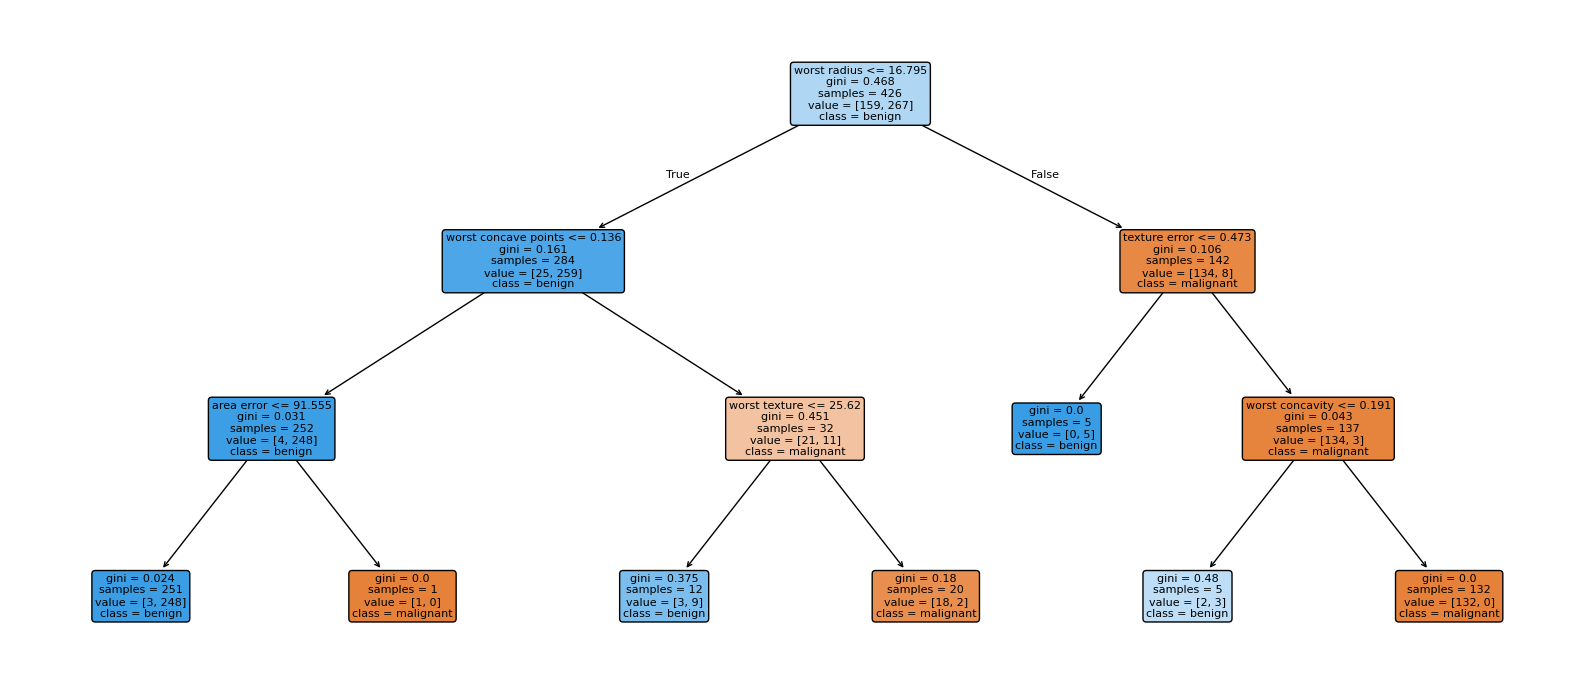

In [13]:
plt.figure(figsize=(16, 7))
plot_tree(DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xtr, ytr), feature_names=names, class_names=list(data.target_names), filled=True, rounded=True, fontsize=8)
plt.tight_layout();

## 7. Conclusions
- The from-scratch tree matches scikit-learn's predictions on the test set.
- Training accuracy reaches 100% at larger depths while test accuracy peaks earlier, which is overfitting.
- A Random Forest improves on a single tree by averaging many high-variance trees.
- Caveat: results come from one split of a small test set; k-fold cross-validation would give tighter estimates.